# 01 — Exploratory analysis

Answers the Phase 3 questions that decide the features and model design. Every chart is saved to
`reports/figures/` for the README and write-up; the two net-flow maps are saved as HTML.

**Run it**
- **Locally:** open from the repo's `notebooks/` folder after `python -m src.ingest.station_hour`.
- **Colab:** put the processed Parquet files in
  `My Drive/Bike-Share Demand Forecasting/data/processed/`; the first cell mounts Drive and copies them.

Data: Citi Bike trips Oct 2025 – Sep 2026 (45.2M after cleaning), hourly weather from Open-Meteo,
live station snapshots from GBFS.

In [1]:
import os

try:  # Colab: mount Drive, copy the Parquet files to local disk (Drive reads are slow)
    from google.colab import drive
    drive.mount('/content/drive')
    !mkdir -p /content/data /content/figures
    !cp "/content/drive/MyDrive/Bike-Share Demand Forecasting/data/processed/"*.parquet /content/data/
    !pip -q install duckdb folium
    D, FIG = '/content/data/', '/content/figures/'
except ImportError:  # local, run from notebooks/
    D, FIG = '../data/processed/', '../reports/figures/'
os.makedirs(FIG, exist_ok=True)

import duckdb
import folium
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

con = duckdb.connect()
con.sql("SET TimeZone = 'UTC'")
for t in ['station_hour', 'stations', 'trips_clean', 'gbfs_status']:
    if os.path.exists(f'{D}{t}.parquet'):
        con.sql(f"CREATE OR REPLACE VIEW {t} AS SELECT * FROM '{D}{t}.parquet'")
    else:
        print(f'missing {t}.parquet — sections that need it will fail')

# The system shut down for a snowstorm; those zeros are real but would distort every average.
SHUTDOWN = ('2026-02-22 20:00', '2026-02-24 05:00')
con.sql(f'''
    CREATE OR REPLACE VIEW sh AS
    SELECT *, hour(ts_local) AS h, month(ts_local) AS m,
           dayofweek(ts_local) IN (0, 6) OR is_holiday AS offday,
           ts_local BETWEEN '{SHUTDOWN[0]}' AND '{SHUTDOWN[1]}' AS shutdown
    FROM station_hour
''')
# System-wide hourly totals: 8,784 rows, the base for most charts.
con.sql('''
    CREATE OR REPLACE TABLE sys AS
    SELECT ts_utc, any_value(ts_local) AS ts_local, any_value(h) AS h, any_value(m) AS m,
           any_value(offday) AS offday, any_value(shutdown) AS shutdown,
           sum(pickups) AS pickups, any_value(temp_c) AS temp_c,
           any_value(precip_mm) AS precip_mm, any_value(snow_cm) AS snow_cm
    FROM sh GROUP BY ts_utc
''')

# Chart style: one validated categorical palette (blue, orange, aqua, yellow), recessive axes.
C = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100']
POS, NEG = '#2a78d6', '#e34948'  # diverging poles: inflow (blue) vs outflow (red)
plt.rcParams.update({
    'figure.figsize': (9, 4), 'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.color': '#e6e5e1', 'grid.linewidth': 0.8, 'axes.edgecolor': '#b5b4ad',
    'axes.labelcolor': '#52514e', 'xtick.color': '#52514e', 'ytick.color': '#52514e',
    'axes.titlesize': 12, 'axes.titleweight': 'bold', 'lines.linewidth': 2, 'legend.frameon': False,
})

def save(name):
    plt.tight_layout()
    plt.savefig(f'{FIG}{name}.png', dpi=150, bbox_inches='tight')
    plt.show()

con.sql('SELECT count(*) AS station_hours, sum(pickups) AS trips, count(DISTINCT station_id) AS stations FROM sh').show()

┌───────────────┬──────────┬──────────┐
│ station_hours │  trips   │ stations │
│     int64     │  int128  │  int64   │
├───────────────┼──────────┼──────────┤
│      19593385 │ 45212497 │     2432 │
└───────────────┴──────────┴──────────┘



## 1. When do people ride?

Expect two commuter peaks on weekdays and one afternoon peak on weekends and holidays.

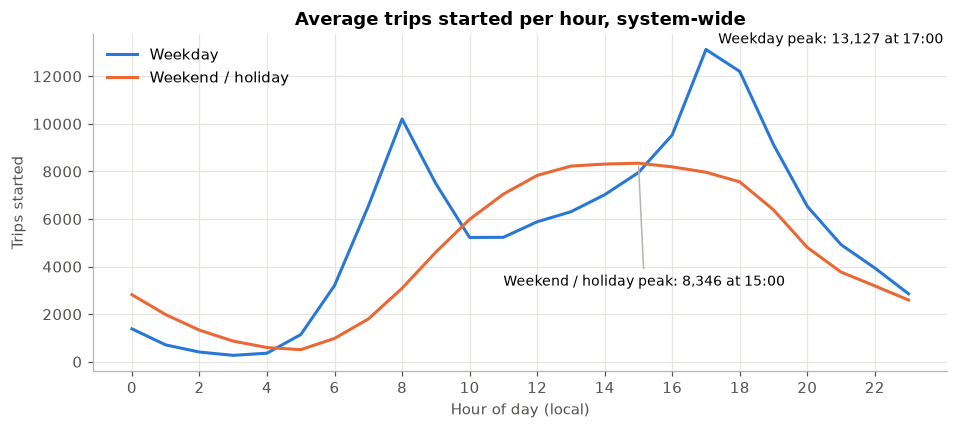

h,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,20,21,22,23
offday,,,,,,,,,,,,,,,,,,,,,
False,1385.0,710.0,409.0,271.0,362.0,1143.0,3205.0,6538.0,10204.0,7488.0,...,7022.0,7952.0,9535.0,13127.0,12203.0,9128.0,6536.0,4923.0,3941.0,2856.0
True,2820.0,1983.0,1330.0,869.0,599.0,510.0,982.0,1798.0,3090.0,4609.0,...,8309.0,8346.0,8193.0,7966.0,7562.0,6387.0,4805.0,3770.0,3190.0,2596.0


In [2]:
q1 = con.sql('''
    WITH d AS (SELECT ts_local::DATE AS day, h, offday, sum(pickups) AS n
               FROM sh WHERE NOT shutdown GROUP BY ALL)
    SELECT h, offday, avg(n) AS avg_pickups FROM d GROUP BY ALL ORDER BY ALL
''').df().pivot(index='h', columns='offday', values='avg_pickups')

fig, ax = plt.subplots()
for col, label, color in [(False, 'Weekday', C[0]), (True, 'Weekend / holiday', C[1])]:
    ax.plot(q1.index, q1[col], color=color, label=label)
    peak = q1[col].idxmax()
    text = f'{label} peak: {q1[col].max():,.0f} at {peak}:00'
    if col:  # weekend label sits in the empty space below both lines
        ax.annotate(text, (peak, q1[col].max()), xytext=(11, 3200), textcoords='data', fontsize=9,
                    arrowprops=dict(arrowstyle='-', color='#b5b4ad'))
    else:
        ax.annotate(text, (peak, q1[col].max()), xytext=(8, 4), textcoords='offset points', fontsize=9)
ax.set(title='Average trips started per hour, system-wide', xlabel='Hour of day (local)',
       ylabel='Trips started', xticks=range(0, 24, 2))
ax.legend(loc='upper left')
save('01_hourly_profile')
q1.round(0).T

## 2. How does demand change over the year?

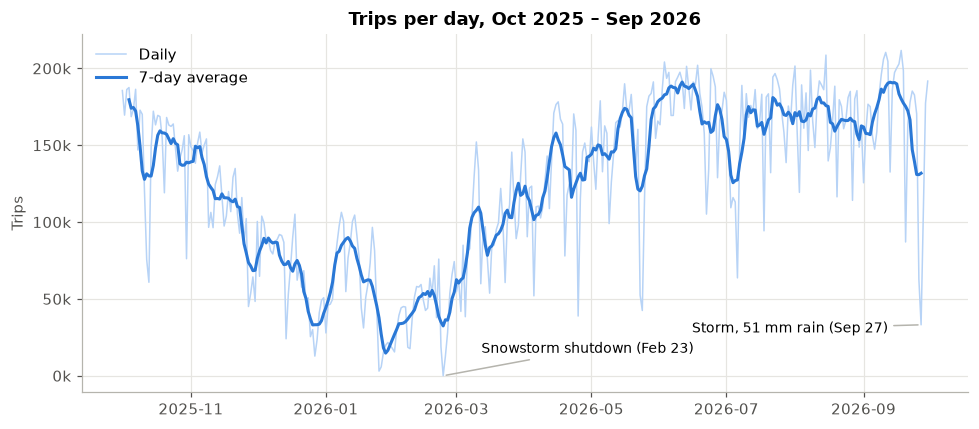

Busiest month: 2026-06 5,366,350.0 | quietest: 2026-02 1,210,352.0 | ratio 4.4x


In [3]:
daily = con.sql('''
    SELECT ts_local::DATE AS day, sum(pickups) AS trips, avg(temp_c) AS temp_c, sum(precip_mm) AS precip_mm,
           bool_or(offday) AS offday, bool_or(shutdown) AS shutdown
    FROM sys GROUP BY 1 ORDER BY 1
''').df()
daily['day'] = pd.to_datetime(daily['day'])

fig, ax = plt.subplots()
ax.plot(daily['day'], daily['trips'], color='#b7d3f6', linewidth=1, label='Daily')
ax.plot(daily['day'], daily['trips'].rolling(7, center=True).mean(), color=C[0], label='7-day average')
sd = daily.loc[daily['trips'].idxmin()]
ax.annotate('Snowstorm shutdown (Feb 23)', (sd['day'], sd['trips']), xytext=(25, 15), textcoords='offset points',
            fontsize=9, arrowprops=dict(arrowstyle='-', color='#b5b4ad'))
storm = daily[daily['day'].dt.strftime('%m-%d') == '09-27'].iloc[0]
ax.annotate('Storm, 51 mm rain (Sep 27)', (storm['day'], storm['trips']), xytext=(-150, -5),
            textcoords='offset points', fontsize=9, arrowprops=dict(arrowstyle='-', color='#b5b4ad'))
ax.set(title='Trips per day, Oct 2025 – Sep 2026', ylabel='Trips')
ax.yaxis.set_major_formatter(lambda v, _: f'{v/1000:.0f}k')
ax.legend(loc='upper left')
save('02_daily_trend')

monthly = daily.groupby(daily['day'].dt.to_period('M'))['trips'].sum()
print('Busiest month:', monthly.idxmax(), f'{monthly.max():,}', '| quietest:', monthly.idxmin(), f'{monthly.min():,}',
      f'| ratio {monthly.max() / monthly.min():.1f}x')

## 3. How much do weather and rain suppress rides?

Daily trips against temperature, then a cleaner hourly test: each hour's trips divided by what a
**dry** hour with the same month, day type and hour of day usually gets.

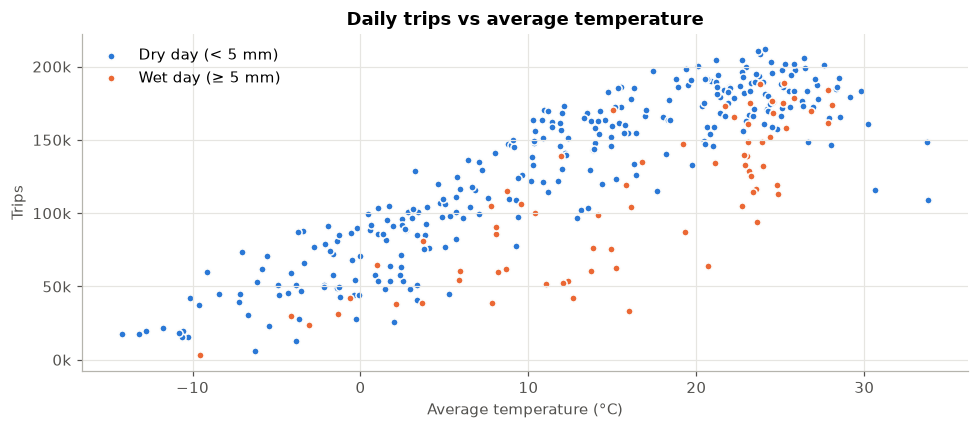

Correlation, daily trips vs temperature: 0.84


In [4]:
d = daily[~daily['shutdown']]
wet = d['precip_mm'] >= 5
fig, ax = plt.subplots()
ax.scatter(d.loc[~wet, 'temp_c'], d.loc[~wet, 'trips'], s=22, color=C[0], label='Dry day (< 5 mm)',
           edgecolor='#fcfcfb', linewidth=1)
ax.scatter(d.loc[wet, 'temp_c'], d.loc[wet, 'trips'], s=22, color=C[1], label='Wet day (≥ 5 mm)',
           edgecolor='#fcfcfb', linewidth=1)
ax.set(title='Daily trips vs average temperature', xlabel='Average temperature (°C)', ylabel='Trips')
ax.yaxis.set_major_formatter(lambda v, _: f'{v/1000:.0f}k')
ax.legend(loc='upper left')
save('03_temperature')
print(f"Correlation, daily trips vs temperature: {d['trips'].corr(d['temp_c']):.2f}")

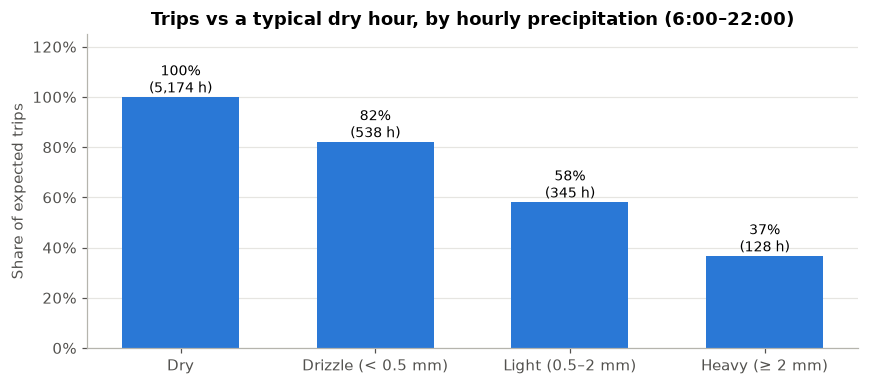

,bucket,hours,ratio
0,Dry,5174,1.000000
1,Drizzle (< 0.5 mm),538,0.821339
2,Light (0.5–2 mm),345,0.581219
3,Heavy (≥ 2 mm),128,0.366866


In [5]:
rain = con.sql('''
    WITH base AS (
        SELECT m, offday, h, avg(pickups) AS expected
        FROM sys WHERE precip_mm = 0 AND NOT shutdown GROUP BY ALL)
    SELECT CASE WHEN precip_mm = 0 THEN '0 Dry'
                WHEN precip_mm < 0.5 THEN '1 Drizzle (< 0.5 mm)'
                WHEN precip_mm < 2 THEN '2 Light (0.5–2 mm)'
                ELSE '3 Heavy (≥ 2 mm)' END AS bucket,
           count(*) AS hours, sum(pickups) / sum(expected) AS ratio
    FROM sys JOIN base USING (m, offday, h)
    WHERE NOT shutdown AND h BETWEEN 6 AND 22
    GROUP BY 1 ORDER BY 1
''').df()
rain['bucket'] = rain['bucket'].str[2:]

fig, ax = plt.subplots(figsize=(8, 3.6))
bars = ax.bar(rain['bucket'], rain['ratio'], color=C[0], width=0.6)
for b, r, n in zip(bars, rain['ratio'], rain['hours']):
    ax.annotate(f'{r:.0%}\n({n:,} h)', (b.get_x() + b.get_width() / 2, r), xytext=(0, 3),
                textcoords='offset points', ha='center', fontsize=9)
ax.set(title='Trips vs a typical dry hour, by hourly precipitation (6:00–22:00)',
       ylabel='Share of expected trips', ylim=(0, 1.25))
ax.yaxis.set_major_formatter(lambda v, _: f'{v:.0%}')
ax.grid(axis='x', visible=False)
ax.set_axisbelow(True)
save('04_rain_effect')
rain

## 4. Which stations are sources and sinks?

Average net flow (drop-offs − pick-ups) per weekday, in the morning (7–10) and evening (16–19) peaks.
**Red = source** (bikes leave, station drains), **blue = sink** (bikes arrive, station fills).
Hover a circle for the station and value.

In [6]:
def net_flow_map(h0, h1, name):
    f = con.sql(f'''
        SELECT s.station_id, s.name, s.lat, s.lng,
               sum(net_flow) / count(DISTINCT ts_local::DATE) AS flow
        FROM sh JOIN stations s USING (station_id)
        WHERE NOT offday AND NOT shutdown AND h >= {h0} AND h < {h1}
        GROUP BY ALL
    ''').df()
    m = folium.Map(location=[40.735, -73.96], zoom_start=12, tiles='CartoDB positron')
    for r in f.itertuples():
        if abs(r.flow) < 0.5:
            continue
        folium.CircleMarker(
            [r.lat, r.lng], radius=min(2 + 1.6 * abs(r.flow) ** 0.5, 14), weight=1, color='#fcfcfb',
            fill=True, fill_color=POS if r.flow > 0 else NEG, fill_opacity=0.8,
            tooltip=f'{r.name}: {r.flow:+.1f} bikes/day ({"sink" if r.flow > 0 else "source"})',
        ).add_to(m)
    m.save(f'{FIG}{name}.html')
    return f, m

am, am_map = net_flow_map(7, 10, 'map_netflow_morning')
am_map

C:\Bike-Share Demand Forecasting\.venv\Lib\site-packages\folium\raster_layers.py:130: UserWarning: CartoDB tiles now require an API key. Please provide one to continue using the tiles. You can request the key at https://carto.com/basemaps/apikey/.
  tiles = tiles.build_url(fill_subdomain=False, scale_factor="{r}")  # type: ignore


In [7]:
pm, pm_map = net_flow_map(16, 19, 'map_netflow_evening')
pm_map

In [8]:
both = am.merge(pm[['station_id', 'flow']], on='station_id', suffixes=('_am', '_pm'))
print(f"Morning vs evening net flow correlation: {both['flow_am'].corr(both['flow_pm']):.2f} "
      "(negative = stations reverse direction between peaks)")
cols = ['name', 'flow_am', 'flow_pm']
display(both.nsmallest(8, 'flow_am')[cols].round(1).rename(columns={'name': 'Top morning sources'}))
display(both.nlargest(8, 'flow_am')[cols].round(1).rename(columns={'name': 'Top morning sinks'}))

Morning vs evening net flow correlation: -0.94 (negative = stations reverse direction between peaks)


,Top morning sources,flow_am,flow_pm
1867,W 43 St & 10 Ave,-57.3,39.1
2237,E 10 St & Ave A,-45.0,29.0
251,Riverside Blvd & W 67 St,-43.4,32.4
2034,W 44 St & 11 Ave,-42.6,24.9
628,FDR Drive & E 35 St,-42.3,53.3
1669,E 2 St & Ave B,-41.9,17.3
313,E 6 St & Ave B,-41.1,17.5
1769,Grand St & Samuel Dickstein Plaza,-41.0,17.2


,Top morning sinks,flow_am,flow_pm
1932,9 Ave & W 33 St,104.8,-100.6
818,E 47 St & Park Ave,73.7,-73.7
846,Greenwich St & Hubert St,67.1,-61.8
2103,Broadway & W 25 St,64.3,-53.9
1276,Dock 72 Way & Market St,62.1,-58.8
847,North Moore St & Greenwich St,59.5,-90.1
905,E 40 St & 5 Ave,54.7,-52.8
1613,1 Ave & E 68 St,53.9,-72.8


## 5. How skewed is demand across stations?

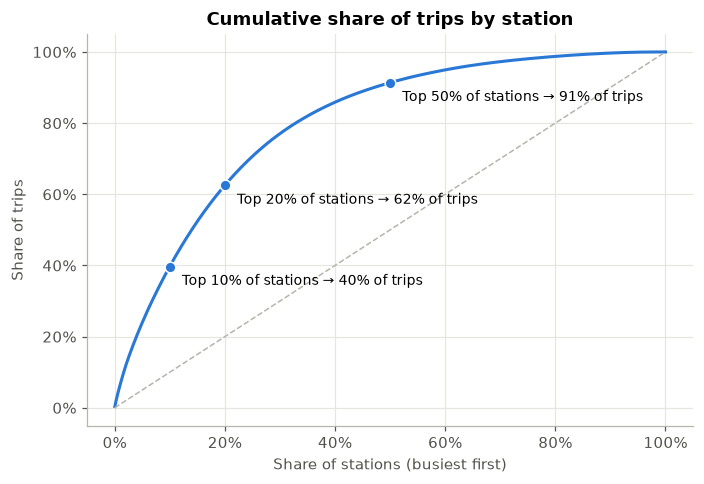

Median station: 22.3 trips/day | busiest: 450/day | stations under 5 trips/day: 16%


In [9]:
tot = con.sql('SELECT station_id, sum(pickups) AS n FROM sh GROUP BY 1 ORDER BY n DESC').df()
share_st = np.arange(1, len(tot) + 1) / len(tot)
share_tr = tot['n'].cumsum() / tot['n'].sum()

fig, ax = plt.subplots(figsize=(6.5, 4.5))
ax.plot(share_st, share_tr, color=C[0])
ax.plot([0, 1], [0, 1], color='#b5b4ad', linewidth=1, linestyle='--')
for p in (0.1, 0.2, 0.5):
    y = share_tr.iloc[int(p * len(tot)) - 1]
    ax.plot(p, y, 'o', color=C[0], markersize=7, markeredgecolor='#fcfcfb')
    ax.annotate(f'Top {p:.0%} of stations → {y:.0%} of trips', (p, y), xytext=(8, -12),
                textcoords='offset points', fontsize=9)
ax.set(title='Cumulative share of trips by station', xlabel='Share of stations (busiest first)',
       ylabel='Share of trips')
ax.xaxis.set_major_formatter(lambda v, _: f'{v:.0%}')
ax.yaxis.set_major_formatter(lambda v, _: f'{v:.0%}')
save('05_station_skew')
q = tot['n'] / 365
print(f"Median station: {q.median():.1f} trips/day | busiest: {q.max():.0f}/day | "
      f"stations under 5 trips/day: {(q < 5).mean():.0%}")

## 6. How often do stations actually run empty or full?

From the live GBFS snapshots (collected since Oct 15, 2026). This sets the base rate for alerts.
Only stations that are installed and renting count. **The sample is still small** — rerun as the
collector accumulates weeks of data.

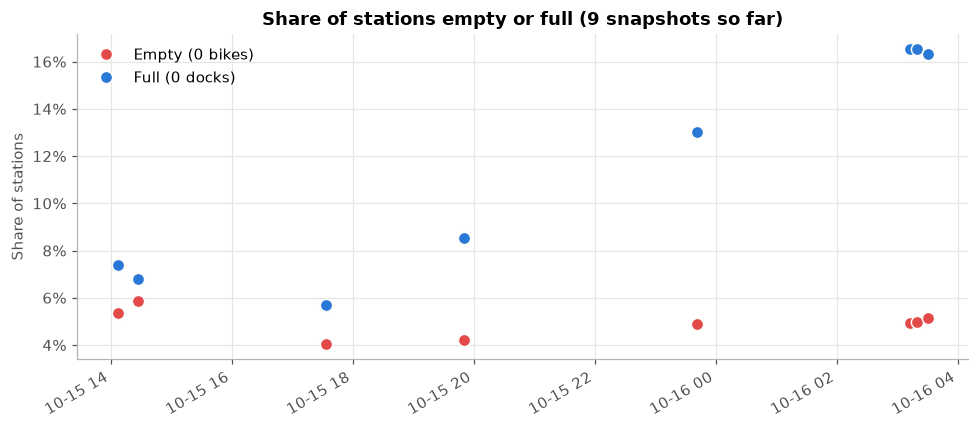

Average: 5.0% of stations empty, 10.9% full at any moment (9 snapshots, 4 after a feed gap)


In [10]:
so = con.sql('''
    SELECT fetched_at::VARCHAR AS fetched_at, any_value(after_outage) AS after_outage,
           count(*) AS stations,
           avg((num_bikes_available = 0)::INT) AS empty,
           avg((num_docks_available = 0)::INT) AS full
    FROM gbfs_status WHERE is_installed = 1 AND is_renting = 1
    GROUP BY 1 ORDER BY 1
''').df()
so['t'] = pd.to_datetime(so['fetched_at'].str[:19]).dt.tz_localize('UTC').dt.tz_convert('America/New_York')

fig, ax = plt.subplots()
# Markers only: connecting lines would draw data across feed gaps.
ax.plot(so['t'], so['empty'], 'o', color=NEG, markersize=8, markeredgecolor='#fcfcfb', label='Empty (0 bikes)')
ax.plot(so['t'], so['full'], 'o', color=C[0], markersize=8, markeredgecolor='#fcfcfb', label='Full (0 docks)')
ax.set(title=f'Share of stations empty or full ({len(so)} snapshots so far)', ylabel='Share of stations')
ax.yaxis.set_major_formatter(lambda v, _: f'{v:.0%}')
ax.legend(loc='upper left')
fig.autofmt_xdate()
save('06_stockouts')
print(f"Average: {so['empty'].mean():.1%} of stations empty, {so['full'].mean():.1%} full at any moment "
      f"({len(so)} snapshots, {so['after_outage'].sum()} after a feed gap)")

## 7. Do members and casual riders behave differently?

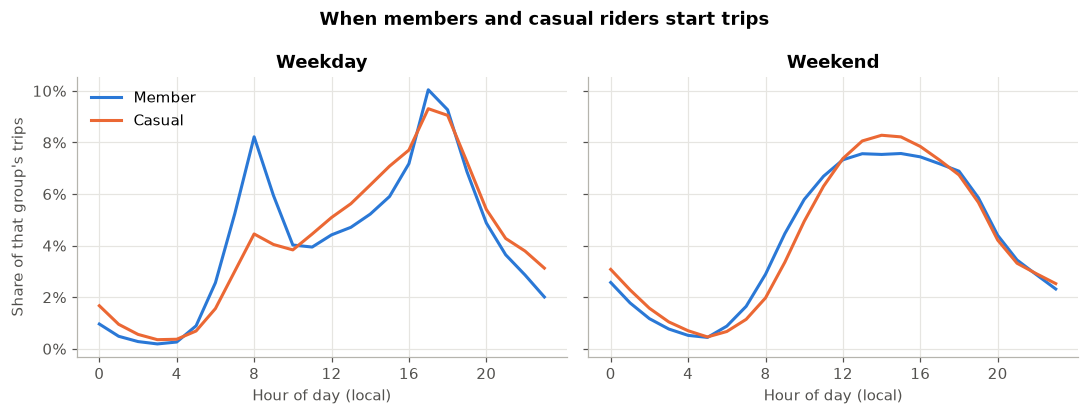

weekend
weekday    15% casual
weekend    24% casual


In [11]:
mc = con.sql('''
    WITH t AS (SELECT member_casual, timezone('America/New_York', started_utc) AS ts FROM trips_clean)
    SELECT member_casual, dayofweek(ts) IN (0, 6) AS weekend, hour(ts) AS h, count(*) AS n
    FROM t GROUP BY ALL
''').df()
mc['share'] = mc['n'] / mc.groupby(['member_casual', 'weekend'])['n'].transform('sum')

fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), sharey=True)
for ax, wk, title in zip(axes, [False, True], ['Weekday', 'Weekend']):
    for who, color in [('member', C[0]), ('casual', C[1])]:
        s = mc[(mc.member_casual == who) & (mc.weekend == wk)].sort_values('h')
        ax.plot(s['h'], s['share'], color=color, label=who.title())
    ax.set(title=title, xlabel='Hour of day (local)', xticks=range(0, 24, 4))
axes[0].set_ylabel("Share of that group's trips")
axes[0].yaxis.set_major_formatter(lambda v, _: f'{v:.0%}')
axes[0].legend(loc='upper left')
fig.suptitle('When members and casual riders start trips', fontweight='bold')
save('07_member_casual')

tot_mc = mc.groupby(['weekend', 'member_casual'])['n'].sum().unstack()
print((tot_mc['casual'] / tot_mc.sum(axis=1)).rename(lambda w: 'weekend' if w else 'weekday')
      .map('{:.0%} casual'.format).to_string())

## 8. Station clusters

k-means on each station's average **weekday** 24-hour shape (pick-ups and drop-offs, 48 values,
scaled to sum to 1 so clusters capture *when*, not *how much*). Fit on the training months only
(Oct 2025 – Jun 2026) so the cluster feature doesn't leak validation or test data. Stations with
fewer than 5 trips per weekday are too noisy to cluster and get cluster −1.

In [12]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

prof = con.sql('''
    SELECT station_id, h, avg(pickups) AS pu, avg(dropoffs) AS dr
    FROM sh WHERE ts_local < '2026-07-01' AND NOT offday AND NOT shutdown
    GROUP BY ALL
''').df().pivot(index='station_id', columns='h', values=['pu', 'dr']).fillna(0)
volume = prof.sum(axis=1)
X = prof[volume >= 5]
X = X.div(X.sum(axis=1), axis=0)
for k in range(3, 7):
    lab = KMeans(k, n_init=10, random_state=0).fit_predict(X)
    print(f'k={k}: silhouette {silhouette_score(X, lab):.3f}')

k=3: silhouette 0.113
k=4: silhouette 0.106


k=5: silhouette 0.101
k=6: silhouette 0.089


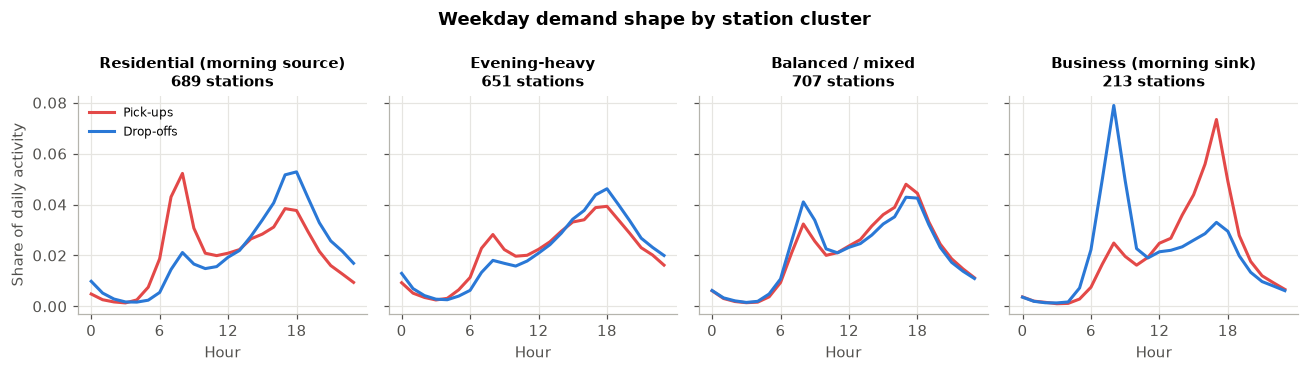

cluster_name
Balanced / mixed                707
Residential (morning source)    689
Evening-heavy                   651
Business (morning sink)         213
Low volume                       53
Name: count, dtype: int64

In [13]:
K = 4
km = KMeans(K, n_init=10, random_state=0).fit(X)
centers = pd.DataFrame(km.cluster_centers_, columns=X.columns)

# Name clusters by their morning-peak behaviour so names survive a rerun with new data.
am_net = (centers['dr'][[7, 8, 9]].sum(axis=1) - centers['pu'][[7, 8, 9]].sum(axis=1))
order = am_net.sort_values().index  # most morning outflow first
names = dict(zip(order, ['Residential (morning source)', 'Evening-heavy', 'Balanced / mixed',
                         'Business (morning sink)']))

fig, axes = plt.subplots(1, K, figsize=(12, 3.4), sharey=True)
for ax, c in zip(axes, order):
    ax.plot(range(24), centers.loc[c, 'pu'], color=NEG, label='Pick-ups')
    ax.plot(range(24), centers.loc[c, 'dr'], color=POS, label='Drop-offs')
    ax.set(title=f'{names[c]}\n{(km.labels_ == c).sum()} stations', xticks=range(0, 24, 6), xlabel='Hour')
    ax.title.set_fontsize(10)
axes[0].set_ylabel('Share of daily activity')
axes[0].legend(loc='upper left', fontsize=8)
fig.suptitle('Weekday demand shape by station cluster', fontweight='bold')
save('08_clusters')

clusters = pd.DataFrame({'station_id': prof.index, 'cluster': -1})
clusters.loc[clusters['station_id'].isin(X.index), 'cluster'] = km.labels_
clusters['cluster_name'] = clusters['cluster'].map(names).fillna('Low volume')
clusters.to_parquet(f'{D}station_clusters.parquet', index=False)
clusters['cluster_name'].value_counts()

## Findings → modeling decisions

**In three sentences:** Demand is driven by the commute on weekdays (peaks at 8:00 and 17:00) and by
leisure on weekends (one 12:00–16:00 plateau), scaled up or down by temperature (4.4× more trips in June
than February) and cut sharply by rain. A small share of stations carries most trips: the busiest 10%
handle 40% of them. These busy stations, and the business and residential clusters, are where morning
and evening flows run in opposite directions and stations drain or fill.

| # | Finding | Modeling decision |
|---|---|---|
| 1 | Weekdays have two commuter peaks (10.2k trips at 8:00, 13.1k at 17:00); weekends and holidays have one plateau (~8.3k, 12:00–16:00). | Hour × day-type is the core signal: use `hour`, `dow`, and a weekend-or-holiday flag (holidays behave like weekends). Trees learn the interaction without cyclic encoding. |
| 2 | Strong seasonality: 5.37M trips in June 2026 vs 1.21M in February (4.4×). Daily trips track temperature (r = 0.84) but dip again above ~30 °C. | Temperature is a must-have feature. Training months (Oct–Jun) are mostly colder than validation and test (Jul–Sep), so add level-tracking features (rolling 7-day mean, same-hour mean over the last 4 weeks) so the model is not stuck at the winter level. |
| 3 | Rain suppresses rides steeply: drizzle → 82% of a dry hour, light rain → 58%, heavy (≥ 2 mm/h) → 37%. | Hourly precipitation plus a rain flag. The effect is non-linear, which suits trees. At serving time this comes from a forecast, so precipitation forecast error will be a visible error source. |
| 4 | Extreme days: the system **shut down** from Feb 22, 20:00 to Feb 24, 05:00 (snowstorm), Jan 25 had only 3k trips, and **Sep 26–28 (test month) had a 51 mm storm** (33k trips on Sep 27). | Add a `shutdown` flag and drop those hours from training targets and from lag/rolling inputs. Report test-month error **with and without** Sep 26–28 so one storm doesn't hide or inflate the model's quality. |
| 5 | Morning and evening net flow are mirror images (station correlation −0.94): commuter stations drain in one peak and fill in the other. | Station identity carries the pattern: cluster as a feature, plus per-station hourly profile encodings computed on training months only. The decision layer must expect the same station to need opposite moves at 8:00 and 18:00. |
| 6 | Demand is skewed: the top 10% of stations carry 40% of trips and the top 20% carry 62%. The median station sees 22 trips/day, and 16% see fewer than 5. | Use a Poisson/Tweedie objective (many zeros, count data). Report MAE together with WAPE and break errors down by cluster and volume tier, so quiet stations don't flatter overall MAE. |
| 7 | At any moment ~5% of stations are empty and ~11% are full. **Preliminary:** only 9 snapshots so far. | Full-dock risk is as frequent as empty risk, so alerts need both directions. Re-run this section after 2+ weeks of collection to set the alert base rate. |
| 8 | Members make 85% of weekday trips; casual riders go from 15% of trips on weekdays to 24% on weekends and have almost no 8:00 peak. | One model is enough for now. Optionally add each station's casual share (training months only) as a feature for tourist/park stations. |
| 9 | k-means finds 4 weekday shapes: residential (689 stations, morning source), evening-heavy (651), balanced (707), business (213, morning sink), plus 53 low-volume stations. Silhouette is only ~0.1, so the shapes form a continuum rather than crisp groups. | Use the cluster as a coarse feature and a reporting dimension (saved to `station_clusters.parquet`). Don't rely on it alone; give the model station-level profile features too. |
